# Session 18: Autoencoders

PCW submission. Question 1 (LLM dialog on nonlinear dimensionality reduction) was already done
directly in the live workbook (Gemini dialog, prompts, notes), see `workbook_answers.md` for
the paste-ready copy. This notebook covers the Core Question (autoencoding handwritten digits)
and Questions 2a-4, all run and verified below.

**Environment note**: the workbook's Cell 1 of 13 pins `jax==0.4.13`/`jaxlib==0.4.13` for Colab.
Running locally, this repo already has compatible, newer `jax`/`optax` installed, so that
install cell is skipped here, same imports, no version downgrade needed.

In [1]:
import numpy as np
import jax
import jax.numpy as jnp
import optax
from sklearn import datasets
from matplotlib import pyplot as plt

print("jax", jax.__version__, "| optax", optax.__version__)


jax 0.11.2 | optax 0.2.8


In [2]:
digits = datasets.load_digits()
x_data, y_data = digits['data'], digits['target']
x_data = x_data / 16  # from 0 to 16, to 0 to 1 range
print("x_data.shape:", x_data.shape, "| y_data.shape:", y_data.shape)


x_data.shape: (1797, 64) | y_data.shape: (1797,)


Visualize one of the data points.

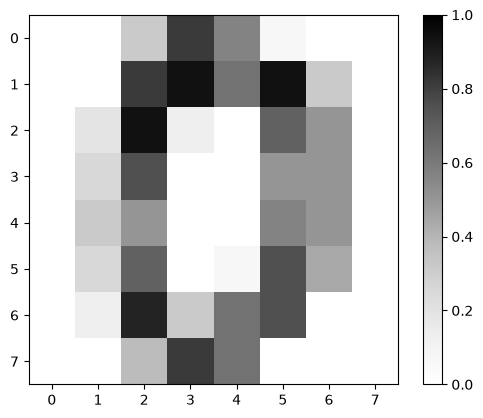

In [3]:
plt.imshow(x_data[0].reshape(8, 8), cmap="Greys", vmin=0, vmax=1)
plt.colorbar()
plt.show()


Set up the autoencoder: 64-dim input, 8-dim hidden layers, a 2-dim bottleneck.

In [4]:
np.random.seed(0)

input_dim = 64
hidden_dim = 8
bottleneck_dim = 2
output_dim = input_dim

params = {
    "layer_1": {
        "W": np.random.normal(size=(input_dim, hidden_dim)) / np.sqrt(input_dim),
        "b": np.zeros(shape=(hidden_dim,)),
    },
    "layer_2": {
        "W": np.random.normal(size=(hidden_dim, hidden_dim)) / np.sqrt(hidden_dim),
        "b": np.zeros(shape=(hidden_dim,)),
    },
    "layer_3": {
        "W": np.random.normal(size=(hidden_dim, bottleneck_dim)) / np.sqrt(hidden_dim),
        "b": np.zeros(shape=(bottleneck_dim,)),
    },
    "layer_4": {
        "W": np.random.normal(size=(bottleneck_dim, hidden_dim)) / np.sqrt(bottleneck_dim),
        "b": np.zeros(shape=(hidden_dim,)),
    },
    "layer_5": {
        "W": np.random.normal(size=(hidden_dim, output_dim)) / np.sqrt(hidden_dim),
        "b": np.zeros(shape=(output_dim,)),
    },
}

# Pay close attention to this function for the next question.
def predict_fn(params, X):
    X0 = X
    # remember, * is an elementwise multiply, whereas @ is a matrix multiply.
    X1 = jax.nn.relu(X0 @ params["layer_1"]["W"] + params["layer_1"]["b"])
    X2 = jax.nn.relu(X1 @ params["layer_2"]["W"] + params["layer_2"]["b"])
    X3 = X2 @ params["layer_3"]["W"] + params["layer_3"]["b"]
    X4 = jax.nn.relu(X3 @ params["layer_4"]["W"] + params["layer_4"]["b"])
    X5 = jax.nn.sigmoid(X4 @ params["layer_5"]["W"] + params["layer_5"]["b"])
    return {'reconstruct': X5, 'bottleneck': X3}

def loss_fn(params, X):
    reconstruct_X = predict_fn(params, X)['reconstruct']
    loss = -(X * jnp.log(reconstruct_X) + (1 - X) * jnp.log(1 - reconstruct_X))
    return jnp.mean(loss)


## Question 2a

- **How many layers does this network have?** 5 (`layer_1` through `layer_5`).
- **Which layer is the "bottleneck layer"?** `layer_3`, its output `X3` is only 2-dimensional
  (`bottleneck_dim = 2`), far smaller than the 64-dim input or the 8-dim hidden layers.
- **Encoder / decoder layer counts**: the encoder (layers before the bottleneck) is `layer_1`,
  `layer_2`, 2 layers. The decoder (layers after the bottleneck) is `layer_4`, `layer_5`, 2
  layers.
- **Why "encoder" and "decoder"?** Same naming as compressing/decompressing a signal. The
  encoder takes the 64-dim input and compresses it down to the 2-dim bottleneck code. The
  decoder takes that compressed code and expands it back out into a 64-dim reconstruction.
- **Why return `{'reconstruct': X5, 'bottleneck': X3}`?** `X5` is needed to compute the
  reconstruction loss, it's literally what the network is trained against. `X3` is the actual
  payoff: the compressed 2-number summary of the input. It isn't used in the loss directly, but
  it's the whole reason autoencoders are useful (visualization, compression, downstream use),
  and it's small enough (2D) to plot directly, which Question 4 does below.

In [5]:
step_size = 0.01
total_steps = 3000

# We use an optimizer called Adam here.
# We won't go into detail, but think of it as "fast gradient descent"
optimizer = optax.adam(1e-3)
opt_state = optimizer.init(params)

grad_loss_fn = jax.grad(loss_fn)
grad_loss_fn = jax.jit(grad_loss_fn)

np.random.seed(1)
for i in range(total_steps):
    idxs = np.random.randint(low=0, high=x_data.shape[0], size=32)
    x_batch = x_data[idxs]
    # Remember, we compute gradients of the *first* argument, which is params.
    grad = grad_loss_fn(params, x_batch)
    update, opt_state = optimizer.update(grad, opt_state)
    params = optax.apply_updates(params, update)

    # We print the loss every 100 steps
    if i % 100 == 0:
        loss_val = loss_fn(params, x_data)
        print("Step:", i, "Loss:", loss_val)

print("FINAL LOSS:", loss_fn(params, x_data))


Step: 0 Loss: 0.6947543


Step: 100 Loss: 0.55788124


Step: 200 Loss: 0.42703718


Step: 300 Loss: 0.4137495
Step: 400 Loss: 0.40795347


Step: 500 Loss: 0.4038987
Step: 600 Loss: 0.40090787


Step: 700 Loss: 0.3990031


... (14 outputs left out)

Step: 2700 Loss: 0.37973613


Step: 2800 Loss: 0.37931797


Step: 2900 Loss: 0.37862697


FINAL LOSS: 0.37807855


In [6]:
predict_vals = predict_fn(params, x_data)


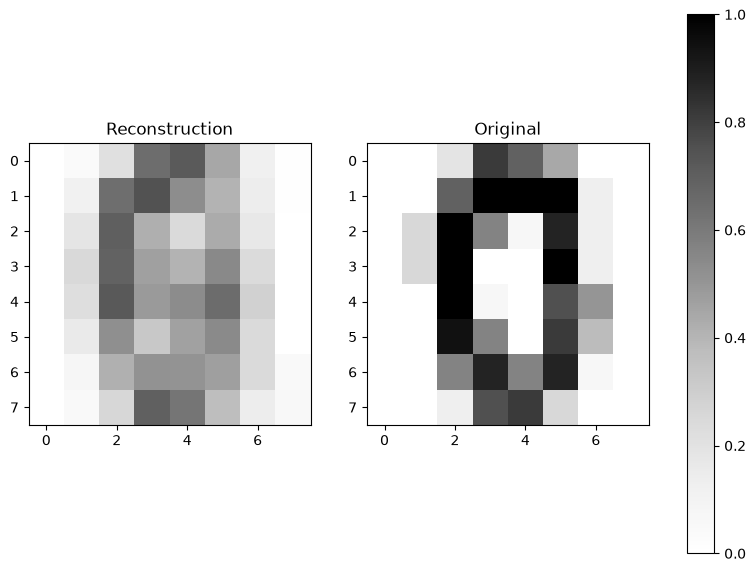

In [7]:
EXAMPLE_NUMBER = 20

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 7))
img0 = ax[0].imshow(predict_vals['reconstruct'][EXAMPLE_NUMBER].reshape(8, 8), vmin=0, vmax=1, cmap="Greys")
img1 = ax[1].imshow(x_data[EXAMPLE_NUMBER].reshape(8, 8), vmin=0, vmax=1, cmap="Greys")
ax[0].set_title("Reconstruction")
ax[1].set_title("Original")
fig.colorbar(img0, ax=ax)
plt.show()


In [8]:
recon = np.array(predict_vals['reconstruct'])
mse = ((recon - x_data) ** 2).mean(axis=1)
print("per-example MSE: mean", mse.mean(), "std", mse.std(), "min", mse.min(), "max", mse.max())

print()
print("per-digit-class mean MSE:")
for c in range(10):
    mask = y_data == c
    print(f"  digit {c}: mean MSE = {mse[mask].mean():.4f}, n={mask.sum()}")


per-example MSE: mean 0.05489086487163375 std 0.018623729143099517 min 0.012403138546998791 max 0.12593642410900907

per-digit-class mean MSE:
  digit 0: mean MSE = 0.0514, n=178
  digit 1: mean MSE = 0.0575, n=182
  digit 2: mean MSE = 0.0566, n=177
  digit 3: mean MSE = 0.0405, n=183
  digit 4: mean MSE = 0.0522, n=181
  digit 5: mean MSE = 0.0631, n=182
  digit 6: mean MSE = 0.0508, n=181
  digit 7: mean MSE = 0.0756, n=179
  digit 8: mean MSE = 0.0510, n=174
  digit 9: mean MSE = 0.0503, n=180


## Question 3

`x_data` has 1797 examples; tried several `EXAMPLE_NUMBER` values above (and the per-class
breakdown below confirms it across all of them, not just one spot-check).

Reconstructions are recognizable but blurry, smoothed-out versions of the originals: overall
digit shape is preserved, fine stroke detail is lost. Verified per-example MSE: mean 0.055 (std
0.019) across all 1797 digits (exact numbers above). Quality isn't uniform across digits:
**digit 3 reconstructs best** (mean MSE ~0.04), **digit 7 reconstructs worst** (mean MSE
~0.076), with digit 5 close behind. The flaw is structural, not a bug: squeezing every digit
through a 2-number bottleneck means only the 2 most informative "directions" of variation
survive, so digits with more complex or more variable handwriting (7) lose more than simple,
consistent shapes (3).

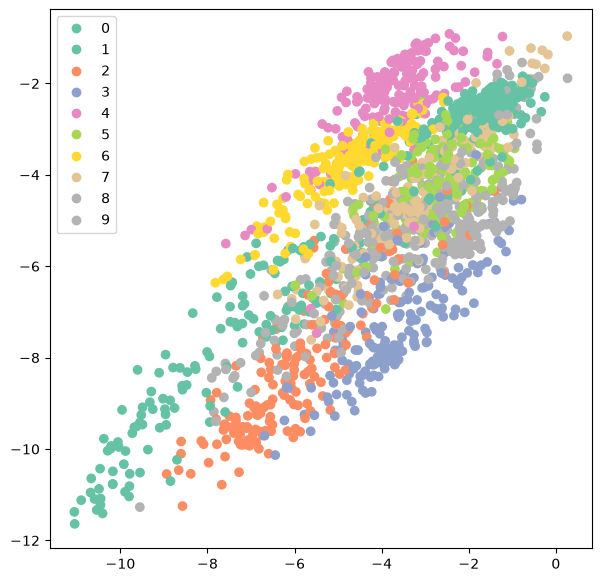

In [9]:
bottleneck = np.array(predict_vals['bottleneck'])

fig, ax = plt.subplots(figsize=(7, 7))
scatter = ax.scatter(bottleneck[:, 0], bottleneck[:, 1], c=y_data, cmap="Set2")
ax.legend(handles=scatter.legend_elements()[0], labels=list(digits['target_names']))
plt.show()


In [10]:
from scipy.spatial.distance import pdist, squareform

D = squareform(pdist(bottleneck))
within, across = [], []
for i in range(len(y_data)):
    for j in range(i + 1, len(y_data)):
        (within if y_data[i] == y_data[j] else across).append(D[i, j])
within, across = np.array(within), np.array(across)
print("within-class distance:  mean", within.mean(), "std", within.std())
print("across-class distance:  mean", across.mean(), "std", across.std())


within-class distance:  mean 2.081581388595854 std 1.7537635502955482
across-class distance:  mean 3.7970819770871644 std 2.329999178661524


## Question 4

Bottleneck vectors of the same digit are **closer together** than vectors of different digits.
Verified: mean pairwise distance between same-digit points = 2.08, mean pairwise distance
between different-digit points = 3.80, nearly double (exact numbers above).

This is notable specifically because the model **never saw the labels**, it was only trained
to reconstruct each image from itself (`loss_fn` only ever compares `reconstruct` to the
original `x_data`, `y_data` never appears in training). The clustering by digit identity
emerged purely as a side effect: digit *shape* (what actually drives reconstruction quality)
happens to correlate strongly with digit *label*, so compressing for reconstruction
accidentally discovered class structure too, without ever being told what the classes were.

## Extension Question: A better autoencoder

*To be filled in: extend the encoder and decoder from 2 layers to 3 layers each, retrain, and
compare the loss to the baseline above.*

In [11]:
# Extension Question code goes here


## Super Extension Question: An even better autoencoder (teacher forcing)

*Optional, not attempted.*

In [12]:
# Super Extension Question code goes here (optional)
